# Module 9 — Barrier Analysis

Part of the Root-Cause Analysis Playbook. Program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

- The 5 Whys, the fishbone, cause mapping and fault trees (Modules 5 to 8) ask **why the problem happened**. Barrier analysis asks a different question: **why did nothing stop it?**
- Every system has defences between a danger and the thing it could harm. When an incident gets through, some defences failed and some were never there. Listing them shows what to build or fix.
- In DMAIC (Define, Measure, Analyze, Improve, Control), it is an **Improve** tool: its output is the list of defences to fix.

**What this module produces:**
1. A table of every defence in a real incident, each marked worked, failed or missing, with the evidence quoted.
2. How much data each dated copy of the database would have saved.
3. The company's own fix list, matched against that table: does every broken defence get a fix?

## From the curriculum

> ## <u>Module 9 — Barrier Analysis</u>
>
> **DMAIC phase:** Improve (deciding which defences to build or strengthen).
>
> **Concepts**
> - Hazard, target, barrier: what can do harm, what it harms, and what stands
>   in between
> - Prevention barriers (before the hazard) vs. recovery barriers (after it,
>   limiting the harm)
> - Barrier types: physical (in software: technical), administrative
>   (procedures), and detection (monitoring)
> - Barrier states: present and worked, present but failed, missing
> - The "Swiss cheese" model: an incident needs the holes in several layers to
>   line up
>
> **Why it matters**
> Cause-finding asks why the problem happened. Barrier analysis asks why
> nothing stopped it, and so leads straight to what to build.
>
> **Worked example**
> Fresh and real: GitLab's published postmortem (a company's own public
> write-up of an incident) of its 31 January 2017 database incident, in which
> several backup and replication barriers all failed. Only 1 of its 11
> barriers worked, and it was not built as a backup. The company's own fix list is
> matched against the barrier table.
>
> **Resources**
> - [Postmortem of database outage of January 31](https://about.gitlab.com/blog/postmortem-of-database-outage-of-january-31/)
>   (GitLab Blog, 2017, ~20 min, verified): the worked example's source.
> - [Human error: models and management](https://pmc.ncbi.nlm.nih.gov/articles/PMC1117770/)
>   (James Reason, BMJ 2000, ~10 min, verified): the original short paper on
>   the Swiss cheese model.
>
> **Exercise type:** count the fixes that repair prevention vs. recovery
> barriers, and judge the company's choice. Fully worked.
>
> **Interview angle:** "The fix is in. How do you make sure it can't happen
> again?"

## Lesson

### Hazard, target, barrier

- **Hazard:** what can do harm (*"a command that deletes a database's data"*).
- **Target:** what the hazard can harm (*"the users' data"*).
- **Barrier:** anything that stands between the two: it stops the hazard, or limits the harm.

### Two kinds of barrier, by position

- **Prevention barriers** stand before the hazard happens. They stop it, or remove the situation that leads to it (*"a clear sign of which server you are on"*).
- **Recovery barriers** stand after it. They limit the harm once it has happened (*"a backup"*).

### Three types

- **Technical:** built into the system (a backup job, a copy of the database). The curriculum calls these "physical", the term from factories and plants. In software they are technical.
- **Administrative:** procedures and people (a written procedure, an owner who tests the backups).
- **Detection:** something that notices when things go wrong (an alert when a backup fails, a person who spots a mistake).

### Three states

For each barrier, ask what it did in this incident:
- **worked:** it was there and it stopped or limited the harm
- **failed:** it was there, but it did not do its job
- **missing:** it was never there

### The Swiss cheese model

Picture each barrier as a slice of Swiss cheese: every slice has holes. An incident gets through only when the holes in all the slices line up. Two lessons follow:
- No single barrier has to be perfect, but every one has to be **known to work**. A barrier nobody checks can be failing for months.
- The fix is not one perfect barrier. It is enough working slices that their holes never line up.

### How it differs from cause-finding

The 5 Whys or a fault tree ends at a cause: *"why did the data get deleted?"*. Barrier analysis ends at a list of defences: *"what should have stopped it, or limited it, and why didn't it?"*. The two are complementary: the cause tells you what to avoid, and the barriers tell you what to build.

## Worked example: GitLab's database outage, 31 January 2017

**Data choice: fresh (new to this playbook), real.** GitLab published a postmortem (a company's own public write-up of an incident) that names every backup and defence it had, and states plainly which ones failed and why. Few companies publish this much.

**Source:** [Postmortem of database outage of January 31](https://about.gitlab.com/blog/postmortem-of-database-outage-of-january-31/) (GitLab Blog, 2017-02-10). All times are UTC (Coordinated Universal Time), as in the post, and the post marks most of them "±" (approximate). The post never uses the word "barrier": the barriers below are this module's reading of it, each backed by a quote.

**What happened, in a few lines:**
1. GitLab.com ran one main database (the **primary**) and one live copy of it (the **secondary**), kept up to date by **replication**: the primary streams every change to the secondary.
2. On 31 January, heavy load made replication fall behind and break.
3. Fixing it meant rebuilding the secondary (a **re-sync**): deleting its data and copying everything again from the primary. This was done by hand.
4. Late that night, an engineer ran the delete command meaning to wipe the secondary, but ran it on the primary.
5. Every backup they then reached for turned out to be broken or missing, except one copy taken by chance earlier that day.

**Terms in the quotes:**
- **disaster recovery:** getting a system and its data back after a major loss
- **pg_dump:** the standard tool that writes a full backup of a PostgreSQL database (PostgreSQL = the database software)
- **S3 / S3 bucket:** Amazon's file storage, and a folder in it, where the backups were uploaded
- **LVM snapshot / Azure disk snapshot:** a frozen copy of a whole disk at one moment (LVM and Azure are the two systems that take them)
- **WAL:** the database's log of changes (WAL = write-ahead log). **WAL archiving** keeps old log files, so a secondary that falls behind can catch up on its own, with no rebuild.
- **DMARC:** an email signing standard. Without it, the receiving mail server rejected GitLab's backup failure emails.
- **cronjob:** a job a server runs on a schedule
- **staging:** a test copy of the system, separate from the live one (production). Each of the two is an **environment**.
- **host:** a server
- **abuse report:** a user's report that an account is misusing the site (for example, spam)
- **load testing:** testing how a system copes with heavy use
- **GB:** gigabytes
- **PS1:** the command-line prompt, the text that shows before every command (it can show the server's name)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import common
from common import show, BLUE, ORANGE, AQUA, GREY

T = lambda s: pd.Timestamp(s)
hm = lambda td: f"{int(td.total_seconds() // 3600)}h {int(td.total_seconds() % 3600 // 60):02d}m"
deleted = T("2017-01-31 23:30")
print("The incident in numbers (all from the post):")
print("  data deleted from the primary = around 300 GB (the post: \"around 300 GB of data had already been removed\")")
print(f"  deletion = {deleted:%Y-%m-%d %H:%M} UTC (the post: \"± 23:30 UTC\")")
print(f"  database fully restored = {T('2017-02-01 18:00'):%Y-%m-%d %H:%M} UTC (the post: \"Around 18:00 UTC we finished\")")
print(f"  deletion -> fully restored = {hm(T('2017-02-01 18:00') - deleted)} (the post: \"down for about 18 hours\")")
print("  data lost, best estimate (the post: \"Our best estimate is that it affected roughly...\"):")
print("    projects = about 5,000")
print("    comments = about 5,000")
print("    new user accounts = about 700")

The incident in numbers (all from the post):
  data deleted from the primary = around 300 GB (the post: "around 300 GB of data had already been removed")
  deletion = 2017-01-31 23:30 UTC (the post: "± 23:30 UTC")
  database fully restored = 2017-02-01 18:00 UTC (the post: "Around 18:00 UTC we finished")
  deletion -> fully restored = 18h 30m (the post: "down for about 18 hours")
  data lost, best estimate (the post: "Our best estimate is that it affected roughly..."):
    projects = about 5,000
    comments = about 5,000
    new user accounts = about 700


**Observation:** the database was down for 18h 30m (the post rounds it to about 18 hours), and the changes users made in the hours before the deletion were lost for good.

**Data caveat:** the post gives two end times for the lost data. Its opening says changes "between 17:20 and 00:00 UTC" were lost, and its "Data loss impact" section says "between January 31st 17:20 UTC and 23:30 UTC". This module uses 23:30, the time of the deletion.

**Hazard:** a command that deletes a database's data, run during a manual repair.

**Target:** the users' data in the GitLab.com database: projects, issues, comments, accounts. (The code itself and the wikis are stored separately and were not affected.)

### Step 1 — Which barriers stood between the hazard and the target, and what did each do?

Every barrier the post describes, in two groups:
- **prevention:** could have stopped the deletion, or removed the need for the manual repair that led to it
- **recovery:** could have limited the data lost once the deletion happened

In [2]:
rows = [
    ("prevention", "abuse-report review", "administrative", "failed",
     "checking an abuse report before an account and its data are removed",
     "The current system used for responding to abuse reports makes it too easy to overlook the details of those reported.",
     "it existed, but a GitLab employee was wrongly flagged and their data scheduled for removal, which added to the heavy load"),
    ("prevention", "WAL archiving", "technical", "missing",
     "keeping old change-log files, so the secondary can catch up on its own",
     "As GitLab.com was not using WAL archiving, the secondary had to be re-synchronised manually.",
     "it was not in use, so the secondary had to be rebuilt by hand"),
    ("prevention", "re-sync procedure", "administrative", "failed",
     "the written steps for rebuilding the secondary",
     "Restoring this required manual work as this was not automated, nor was it documented properly.",
     "a written procedure existed, but it was not good enough"),
    ("prevention", "clear sign of which server you are on", "technical", "failed",
     "the command-line prompt (PS1) showing which server a command will run on",
     "Update PS1 across all hosts to more clearly differentiate between hosts and environments",
     "this quote is a fix on GitLab's list, so a sign existed, but not a clear one (inferred, not stated)"),
    ("recovery", "engineer stops the command", "detection", "failed",
     "the engineer noticing the mistake and stopping the delete",
     "The engineer terminated the process a second or two after noticing their mistake, but at this point around 300 GB of data had already been removed.",
     "they stopped it within seconds, but it was already too late"),
    ("recovery", "the secondary database", "technical", "failed",
     "the live copy of the database, kept up to date by replication",
     "The secondary database's data was wiped as part of restoring database replication.",
     "the re-sync itself wiped it before the deletion, so it was out of service when needed"),
    ("recovery", "daily pg_dump backups to S3", "technical", "failed",
     "a full backup every 24 hours, uploaded to S3",
     "The S3 bucket was empty, and there was no recent backup to be found anywhere.",
     "the job used the wrong version of pg_dump (9.2, for a 9.6 database), so it stopped with an error every time"),
    ("recovery", "backup failure emails", "detection", "failed",
     "an email to the engineers whenever the backup job fails",
     "DMARC was not enabled for the cronjob emails, resulting in them being rejected by the receiver.",
     "the emails were sent but rejected, so \"we were never aware of the backups failing, until it was too late\""),
    ("recovery", "restore tests, with an owner", "administrative", "missing",
     "someone responsible for checking, regularly, that a backup can really be restored",
     "there was no ownership, as a result nobody was responsible for testing this procedure.",
     "nobody had the job"),
    ("recovery", "Azure disk snapshots", "technical", "missing",
     "a frozen copy of a whole disk, every 24 hours",
     "these snapshots were not enabled for any of the database servers",
     "they were used for other servers, but not for the database: \"we assumed that our other backup procedures were sufficient\""),
    ("recovery", "LVM snapshots", "technical", "worked",
     "a frozen copy of the database disk, made every 24 hours to load into staging",
     "this process was working as intended",
     "the snapshots existed, and one of them was used to restore the database"),
]
B = pd.DataFrame(rows, columns=["position", "barrier", "type", "state", "what", "quote", "why"])
print(f"Every barrier in the post = {len(B)}\n")
show(B[["position", "barrier", "type", "state"]].assign(**{"": range(1, len(B) + 1)})[["", "position", "barrier", "type", "state"]])
print("\nEach barrier: what it is, the evidence quoted from the post, and why it gets its state:")
for _, r in B.iterrows():
    print(f"\n  {r['barrier']} = {r['state']}")
    print(f"    what it is: {r['what']}")
    print(f"    the post: \"{r['quote']}\"")
    print(f"    why {r['state']}: {r['why']}")

Every barrier in the post = 11

    position    barrier                                type            state
 1  prevention  abuse-report review                    administrative  failed
 2  prevention  WAL archiving                          technical       missing
 3  prevention  re-sync procedure                      administrative  failed
 4  prevention  clear sign of which server you are on  technical       failed
 5  recovery    engineer stops the command             detection       failed
 6  recovery    the secondary database                 technical       failed
 7  recovery    daily pg_dump backups to S3            technical       failed
 8  recovery    backup failure emails                  detection       failed
 9  recovery    restore tests, with an owner           administrative  missing
10  recovery    Azure disk snapshots                   technical       missing
11  recovery    LVM snapshots                          technical       worked

Each barrier: what it is, the

**Data caveat:** the state of "clear sign of which server you are on" is inferred, not stated. The post never says what the engineer's screen showed.

**Hypothesis:** a clearer sign would have stopped the deletion. This cannot be checked from the post.

In [3]:
print("How many barriers in each state?\n")
counts = B.groupby(["position", "state"]).size().unstack(fill_value=0)[["worked", "failed", "missing"]]
show(counts, index=True)
print("\nAll barriers:")
for st in ["worked", "failed", "missing"]:
    print(f"  {st} = {(B['state'] == st).sum()}")
print()
print("How many barriers of each type?\n")
show(B.groupby("type").size().rename("barriers").reset_index())

How many barriers in each state?

position    worked  failed  missing
prevention       0       3        1
recovery         1       4        2

All barriers:
  worked = 1
  failed = 7
  missing = 3

How many barriers of each type?

type            barriers
administrative         3
detection              2
technical              6


**Observation:** of the 11 barriers, 1 worked, 7 failed and 3 were missing. None of the prevention barriers worked.

**Observation:** failed outnumbers missing, 7 to 3. Most of the defences were there, but did not work when needed.

### Step 2 — The Swiss cheese picture

Every barrier as a slice: the prevention barriers before the deletion, the recovery barriers after it. Within each group, the slices are in the same order as the barrier table, not in time order.

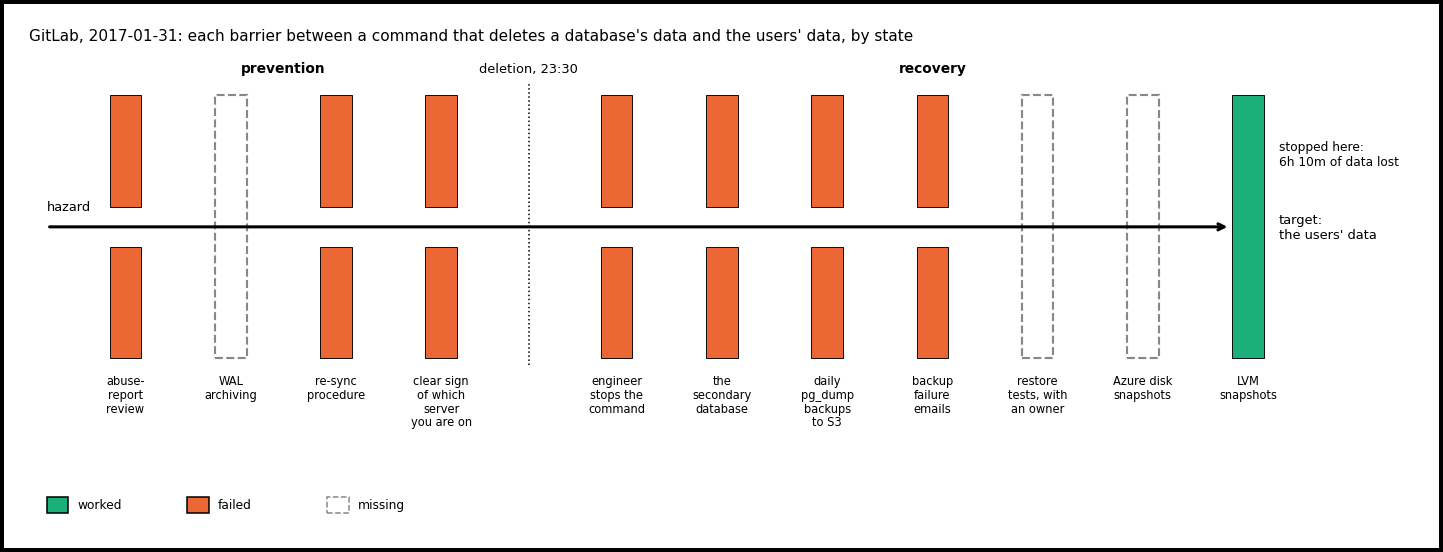

In [4]:
colors = {"worked": AQUA, "failed": ORANGE, "missing": GREY}
short = {"abuse-report review": "abuse-\nreport\nreview", "WAL archiving": "WAL\narchiving", "re-sync procedure": "re-sync\nprocedure",
         "clear sign of which server you are on": "clear sign\nof which\nserver\nyou are on", "engineer stops the command": "engineer\nstops the\ncommand",
         "the secondary database": "the\nsecondary\ndatabase", "daily pg_dump backups to S3": "daily\npg_dump\nbackups\nto S3",
         "backup failure emails": "backup\nfailure\nemails", "restore tests, with an owner": "restore\ntests, with\nan owner",
         "Azure disk snapshots": "Azure disk\nsnapshots", "LVM snapshots": "LVM\nsnapshots"}
fig, ax = plt.subplots(figsize=(13, 4.8))
xs = [1.2 * i + (0.8 if p == "recovery" else 0) for i, p in enumerate(B["position"])]
n_prev = int((B["position"] == "prevention").sum())
for x, (_, r) in zip(xs, B.iterrows()):
    c = colors[r["state"]]
    if r["state"] == "missing":
        ax.add_patch(Rectangle((x - 0.18, 0), 0.36, 4, fill=False, ec=c, lw=1.4, ls="--"))
    elif r["state"] == "failed":
        ax.add_patch(Rectangle((x - 0.18, 0), 0.36, 1.7, fc=c, ec="black", lw=0.6))
        ax.add_patch(Rectangle((x - 0.18, 2.3), 0.36, 1.7, fc=c, ec="black", lw=0.6))
    else:
        ax.add_patch(Rectangle((x - 0.18, 0), 0.36, 4, fc=c, ec="black", lw=0.6))
    ax.text(x, -0.25, short[r["barrier"]], ha="center", va="top", fontsize=7.5)
mid = (xs[n_prev - 1] + xs[n_prev]) / 2
ax.annotate("", xy=(xs[-1] - 0.2, 2.0), xytext=(-0.9, 2.0), arrowprops=dict(arrowstyle="->", color="black", lw=2))
ax.text(-0.9, 2.25, "hazard", fontsize=8.5)
ax.plot([mid, mid], [-0.1, 4.2], color="black", lw=1, ls=":")
ax.text(mid, 4.35, "deletion, 23:30", ha="center", fontsize=8.5)
ax.text((xs[0] + xs[n_prev - 1]) / 2, 4.35, "prevention", ha="center", fontsize=9, fontweight="bold")
ax.text((xs[n_prev] + xs[-1]) / 2, 4.35, "recovery", ha="center", fontsize=9, fontweight="bold")
ax.text(xs[-1] + 0.35, 3.1, f"stopped here:\n{hm(deleted - T('2017-01-31 17:20'))} of data lost", va="center", fontsize=8)
ax.text(xs[-1] + 0.35, 2.0, "target:\nthe users' data", va="center", fontsize=8.5)
for k, (state, c) in enumerate(colors.items()):
    ax.add_patch(Rectangle((-0.9 + k * 1.6, -2.35), 0.25, 0.25, fc=c if state != "missing" else "white", ec=c if state == "missing" else "black", ls="--" if state == "missing" else "-"))
    ax.text(-0.55 + k * 1.6, -2.22, state, va="center", fontsize=8)
ax.set_xlim(-1.1, xs[-1] + 1.9); ax.set_ylim(-2.5, 4.7); ax.axis("off")
ax.set_title("GitLab, 2017-01-31: each barrier between a command that deletes a database's data and the users' data, by state", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

**Observation:** the hazard passed through every slice except the last, the LVM snapshots. Those stopped it only partly: restored from the manual LVM snapshot, 6h 10m of data was still lost.

### Step 3 — How much data would each dated copy have lost?

The data lost is the time between the last good copy and the deletion: everything users changed in that window is gone. Only the two LVM snapshots have a time in the post. (The post gives no time of day for the pg_dump backups, and they were empty anyway.)

In [5]:
copies = [
    ("the daily LVM snapshot", T("2017-01-31 01:00"),
     "This procedure normally happens automatically once every 24 hours (at 01:00 UTC)"),
    ("the manual LVM snapshot", T("2017-01-31 17:20"),
     "± 17:20 UTC: prior to starting this work, our engineer took an LVM snapshot"),
]
print("If the database is restored from this copy, how much data is lost?\n")
show(pd.DataFrame({"copy": [c[0] for c in copies], "taken": [f"{c[1]:%d.%m %H:%M}" for c in copies],
                   "deletion": [f"{deleted:%d.%m %H:%M}"] * len(copies), "data lost": [hm(deleted - c[1]) for c in copies]}))
print("\nThe evidence for each copy's time:")
for c in copies:
    print(f"  {c[0]}:")
    print(f"    \"{c[2]}\"")
print("\nWhat each copy was for, in the post:")
print("  the daily LVM snapshot: \"This snapshot is then loaded into the staging environment, allowing us to more safely test changes without impacting our production environment.\"")
print("  the manual LVM snapshot: \"necessary to ensure the staging database was up to date, allowing for more accurate load testing\"")
print("  LVM snapshots in general: \"the produced snapshots are not really meant to be used for disaster recovery\"")
lost_daily, lost_manual = deleted - copies[0][1], deleted - copies[1][1]
print()
print("How much more data would have been lost without the manual snapshot?")
print(f"  {hm(lost_daily)} ÷ {hm(lost_manual)} = {lost_daily / lost_manual:.1f} times as much")
print()
print("With GitLab's fix of hourly LVM snapshots (\"LVM snapshots are now taken every hour\"):")
print("  the newest copy is at most 1h 00m older than any deletion")
print("  data lost = at most 1h 00m")
print(f"  1h 00m ÷ {hm(lost_manual)} = at most {pd.Timedelta(hours=1) / lost_manual:.2f} times as much as with the manual snapshot")

If the database is restored from this copy, how much data is lost?

copy                     taken        deletion     data lost
the daily LVM snapshot   31.01 01:00  31.01 23:30  22h 30m
the manual LVM snapshot  31.01 17:20  31.01 23:30  6h 10m

The evidence for each copy's time:
  the daily LVM snapshot:
    "This procedure normally happens automatically once every 24 hours (at 01:00 UTC)"
  the manual LVM snapshot:
    "± 17:20 UTC: prior to starting this work, our engineer took an LVM snapshot"

What each copy was for, in the post:
  the daily LVM snapshot: "This snapshot is then loaded into the staging environment, allowing us to more safely test changes without impacting our production environment."
  the manual LVM snapshot: "necessary to ensure the staging database was up to date, allowing for more accurate load testing"
  LVM snapshots in general: "the produced snapshots are not really meant to be used for disaster recovery"

How much more data would have been lost without the

**Observation:** restoring from the manual LVM snapshot lost 6h 10m of data. Restoring from the daily LVM snapshot would have lost 22h 30m: 3.6 times as much.

**Data caveat:** the 22h 30m assumes the daily 01:00 snapshot was taken that day, as the schedule says. The post gives the schedule, not that day's run.

**Conclusion:** the one barrier that worked, the LVM snapshots, was not built as a backup: the daily snapshot exists to load data into staging. If the daily snapshot was taken that day, as scheduled, restoring from it would have lost 22h 30m of data. The copy that cut the loss to 6h 10m was the manual one, taken at 17:20 for load testing, not as a backup.

### Step 4 — Does every failed or missing barrier get a fix?

The post ends with a list of fixes, most of them numbered issues in GitLab's own tracker (the "issue" column). The list's first item is a link to an overview of the others, not a fix, so it is left out. Each fix, matched to the barrier it targets:

In [6]:
fixes = [
    ("#1094", "Update PS1 across all hosts to more clearly differentiate between hosts and environments", "clear sign of which server you are on"),
    ("#1095", "Prometheus monitoring for backups", "backup failure emails"),
    ("#1096", "Set PostgreSQL's max_connections to a sane value", "none (a setting found too high during the repair)"),
    ("#1097", "Investigate Point in time recovery & continuous archiving for PostgreSQL", "WAL archiving"),
    ("#1098", "Hourly LVM snapshots of the production databases", "LVM snapshots"),
    ("#1099", "Azure disk snapshots of production databases", "Azure disk snapshots"),
    ("#1100", "Move staging to the ARM environment", "none (faster restores)"),
    ("#1101", "Recover production replica(s)", "the secondary database"),
    ("#1102", "Automated testing of recovering PostgreSQL database backups", "restore tests, with an owner"),
    ("#1103", "Improve PostgreSQL replication documentation/runbooks", "re-sync procedure"),
    ("#1105", "Investigate pgbarman for creating PostgreSQL backups", "daily pg_dump backups to S3"),
    ("#494", "Investigate using WAL-E as a means of Database Backup and Realtime Replication", "daily pg_dump backups to S3"),
    ("no number", "Build Streaming Database Restore", "none (faster restores)"),
    ("no number", "Assign an owner for data durability", "restore tests, with an owner"),
]
F = pd.DataFrame(fixes, columns=["issue", "fix (as titled in the post)", "barrier it targets"])
num = {b: i for i, b in enumerate(B["barrier"], start=1)}
show(F.assign(**{"barrier it targets": [f"{num[b]}. {b}" if b in num else b for b in F["barrier it targets"]]}))
print()
print("Terms in the fix titles:")
print("  Prometheus = a monitoring system, here pointed at the backups")
print("  max_connections = the database's limit on open connections")
print("  ARM = Azure Resource Manager, Azure's newer setup (staging ran on the older \"Azure classic\", with slow disks)")
print("  replica = another name for a secondary database")
print("  runbook = a written step-by-step procedure")
print("  pgbarman, WAL-E = two existing backup tools for PostgreSQL")
print("  point in time recovery = restoring the database as it was at any chosen moment")
print("  data durability = keeping data safe from loss")
print()
fix_barrier = ~F["barrier it targets"].str.startswith("none")
print(f"Items in the post's list = {len(F) + 1}")
print("  overview link, not a fix = 1")
print(f"  fixes = {len(F) + 1} − 1 = {len(F)}")
print(f"Fixes that target a barrier = {fix_barrier.sum()}")
tgt = F.loc[fix_barrier, "barrier it targets"].value_counts()
twice = ", and ".join(f"{num[x]}. {x}" for x in sorted(tgt[tgt > 1].index, key=num.get))
print(f"Barriers targeted = {len(tgt)} (two barriers get two fixes each: {twice})")
print(f"Fixes that target no barrier = {(~fix_barrier).sum()}")
print(f"Fixes titled \"Investigate\" (a study, not yet a fix) = {F['fix (as titled in the post)'].str.startswith('Investigate').sum()}")

issue      fix (as titled in the post)                                                               barrier it targets
#1094      Update PS1 across all hosts to more clearly differentiate between hosts and environments  4. clear sign of which server you are on
#1095      Prometheus monitoring for backups                                                         8. backup failure emails
#1096      Set PostgreSQL's max_connections to a sane value                                          none (a setting found too high during the repair)
#1097      Investigate Point in time recovery & continuous archiving for PostgreSQL                  2. WAL archiving
#1098      Hourly LVM snapshots of the production databases                                          11. LVM snapshots
#1099      Azure disk snapshots of production databases                                              10. Azure disk snapshots
#1100      Move staging to the ARM environment                                                    

In [7]:
broken = B[B["state"] != "worked"]
per = broken[["position", "barrier", "state"]].copy()
per.insert(0, "", [num[x] for x in per["barrier"]])
per["fixes"] = [int((F["barrier it targets"] == b).sum()) for b in per["barrier"]]
print("Fixes per failed or missing barrier:\n")
show(per)
print()
print(f"Failed or missing barriers with at least one fix in the list = {(per['fixes'] > 0).sum()} of {len(per)}")
print(f"Failed or missing barriers with no fix in the list = {(per['fixes'] == 0).sum()} of {len(per)}")
for b in per.loc[per["fixes"] == 0, "barrier"]:
    print(f"  {b}")
print()
print("What the post says about these two, outside the list:")
print("  abuse-report review: \"Finally, we're looking into improving our abuse reporting and response system.\"")
print("  engineer stops the command: the post's focus is on recovery \"instead of preventing production engineers from running certain commands\"")

Fixes per failed or missing barrier:

    position    barrier                                state    fixes
 1  prevention  abuse-report review                    failed       0
 2  prevention  WAL archiving                          missing      1
 3  prevention  re-sync procedure                      failed       1
 4  prevention  clear sign of which server you are on  failed       1
 5  recovery    engineer stops the command             failed       0
 6  recovery    the secondary database                 failed       1
 7  recovery    daily pg_dump backups to S3            failed       2
 8  recovery    backup failure emails                  failed       1
 9  recovery    restore tests, with an owner           missing      2
10  recovery    Azure disk snapshots                   missing      1

Failed or missing barriers with at least one fix in the list = 8 of 10
Failed or missing barriers with no fix in the list = 2 of 10
  abuse-report review
  engineer stops the command

What th

**Observation:** 8 of the 10 failed or missing barriers get at least one fix in the list. Two get two fixes: "daily pg_dump backups to S3" and "restore tests, with an owner". Three fixes are studies ("Investigate…"), not yet fixes.

**Observation:** 2 barriers get no fix in the list:
- **abuse-report review:** the post promises to improve it in a sentence after the list.
- **engineer stops the command:** no fix anywhere in the post.

**Hypothesis:** "engineer stops the command" is left open on purpose. It fits the post's stated choice to focus on recovery "instead of preventing production engineers from running certain commands", though that sentence is about preventing commands, not stopping them.

**Observation:** the fix targeting "backup failure emails" (#1095, "Prometheus monitoring for backups") adds monitoring. No fix in the list mentions DMARC, the cause of the rejected emails.

**Conclusion:** matching the fix list to the barrier table shows at a glance which barriers the fixes cover, and which they leave open. The table only covers barriers the post describes. A barrier the post never mentions (for example, a second person checking every command on the live database) would not show up.

## Exercise — Why put the fixes after the deletion?

The interview question: *"The fix is in. How do you make sure it can't happen again?"*

GitLab chose to put most of its fixes into recovery barriers rather than prevention barriers. The post explains why:

> "Our main focus is to improve disaster recovery, and making it more obvious as to what host you're using; instead of preventing production engineers from running certain commands. For example, one could alias rm to something safer but in doing so would only protect themselves against accidentally running rm -rf /important-data, not against disk corruption or any of the many other ways you can lose data."

(rm is the delete command. "rm -rf" deletes a folder and everything in it, without asking. An alias would replace rm with a safer version.)

1. Count the fixes that target a prevention barrier and those that target a recovery barrier.
2. Is GitLab's choice sound? The hazard was a command that deletes a database's data. The target was the users' data.

In [8]:
side = F.merge(B[["barrier", "position"]], left_on="barrier it targets", right_on="barrier", how="left")
print("Fixes that target a barrier, by position:")
for pos in ["prevention", "recovery"]:
    print(f"  {pos} = {(side['position'] == pos).sum()}")

Fixes that target a barrier, by position:
  prevention = 3
  recovery = 8


**Answer:**
1. Of the 11 fixes that target a barrier, 3 target a prevention barrier and 8 target a recovery barrier.
2. Yes, for the data. A prevention barrier usually stops **one** hazard: a safer delete command stops only an accidental delete. A recovery barrier, like a recent backup, protects the target, the users' data, from **many** hazards: a wrong command, a disk failure, a bug. The post makes the same argument.

**Observation:** the outage lasted 18h 30m, from the deletion to the full restore.

**Hypothesis:** for downtime, as opposed to lost data, recovery barriers help less: a backup brings the data back, but restoring it can still take hours. The fix list also includes two fixes for faster restores: #1100 and "Build Streaming Database Restore".

## Key takeaways

- **Barrier analysis asks why nothing stopped the incident**, not why it happened. Its output is a list of defences to build or fix.
- **Every barrier is worked, failed or missing.** In GitLab's incident, of 11 barriers, 1 worked, 7 failed and 3 were missing.
- **Most defences were there, but did not work.** The backups were empty and the backup failure emails were being rejected: "we were never aware of the backups failing, until it was too late". A barrier nobody checks can be failing without anyone knowing.
- **The one barrier that worked was not built as a backup.** The daily LVM snapshot exists to load data into staging. The copy that saved most data was the manual LVM snapshot, taken that afternoon for load testing: without it, 22h 30m of data would have been lost instead of 6h 10m (if the daily snapshot ran as scheduled).
- **Match the fix list to the barrier table.** It shows which barriers get a fix and which are left open. GitLab's list covers 8 of the 10 failed or missing barriers.
- **Recovery barriers protect the target from many hazards.** Prevention barriers stop one hazard at a time.
- **In DMAIC, this is Improve:** the barrier table is the list of what to fix.